# Metrics and Distances

**A single companion for the whole “Metrics” section of the lecture notes.**

We build the nine distances in the notes, in the same order:

1. point metrics: **Euclidean**, **Manhattan**, **Chebyshev**, **Minkowski**;
2. discrete metrics: **Hamming**, **Jaccard**;
3. distribution metrics: **Hellinger**, **Wasserstein**, **Total variation**.

For each one we state the definition, compute the worked examples from the
notes, visualise the geometry, and check how the choice changes a k-NN
classifier. No result is taken on faith: every claim is computed below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.stats import uniform, wasserstein_distance
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(0)
plt.rcParams.update(
    {
        'figure.figsize': (8, 5),
        'axes.grid': True,
        'grid.alpha': 0.3,
        'axes.spines.top': False,
        'axes.spines.right': False,
    }
)
print('Setup complete')

Setup complete


## 0. What makes a distance a metric?

A function $d$ on a set $X$ is a metric if for all $x,y,z\in X$:

1. $d(x,y)\geq0$ (non-negativity);
2. $d(x,y)=0\iff x=y$ (identity of indiscernibles);
3. $d(x,y)=d(y,x)$ (symmetry);
4. $d(x,z)\leq d(x,y)+d(y,z)$ (triangle inequality).

Jaccard is a metric on **sets**, Hamming on **equal-length strings**, the
$\ell_p$ family on **vectors**, and the last three on **probability
distributions**. Wasserstein additionally needs a notion of distance between
outcomes; that is why it is the right tool for small location shifts.

## 1. The Minkowski family

For $p\geq1$ and $\mathbf{x},\mathbf{y}\in\mathbb{R}^d$,

$$d_p(\mathbf{x},\mathbf{y})=\left(\sum_{i=1}^d |x_i-y_i|^p\right)^{1/p}.$$

The special cases are $p=1$ (Manhattan), $p=2$ (Euclidean), and
$p\to\infty$ (Chebyshev):

$$d_1=\sum_i|x_i-y_i|,\qquad d_2=\sqrt{\sum_i(x_i-y_i)^2},\qquad
d_\infty=\max_i|x_i-y_i|.$$

In [2]:
def minkowski(x, y, p):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    return float(np.sum(np.abs(x - y) ** p) ** (1 / p))


def euclidean(x, y):
    return minkowski(x, y, 2)


def manhattan(x, y):
    return minkowski(x, y, 1)


def chebyshev(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    return float(np.max(np.abs(x - y)))


x, y = (0, 0), (3, 4)
print('pair:', x, y)
print('d1       =', manhattan(x, y))
print('d2       =', euclidean(x, y))
print('d3       =', round(minkowski(x, y, 3), 4))
print('d_inf    =', chebyshev(x, y))
print('3-D d2   =', euclidean((1, 2, 2), (4, 6, 2)))

pair: (0, 0) (3, 4)
d1       = 7.0
d2       = 5.0
d3       = 4.4979
d_inf    = 4.0
3-D d2   = 5.0


In [3]:
A = np.array([x], dtype=float)
B = np.array([y], dtype=float)
checks = {
    'cityblock': cdist(A, B, metric='cityblock')[0, 0],
    'euclidean': cdist(A, B, metric='euclidean')[0, 0],
    'chebyshev': cdist(A, B, metric='chebyshev')[0, 0],
}
print('SciPy cross-checks:')
for name, value in checks.items():
    print(f'  {name:10s} = {value}')

SciPy cross-checks:
  cityblock  = 7.0
  euclidean  = 5.0
  chebyshev  = 4.0


### 1.1 Checking the axioms numerically

We test the four metric axioms on random vectors for $p=2.5$. A failed
triangle inequality is exactly why the notes require $p\geq1$.

In [ ]:
def axiom_report(distance, a, b, c):
    return {
        'nonnegative': distance(a, b) >= 0,
        'identity': distance(a, a) == 0,
        'symmetry': np.isclose(distance(a, b), distance(b, a)),
        'triangle': distance(a, c) <= distance(a, b) + distance(b, c) + 1e-12,
    }


a, b, c = rng.normal(size=(3, 6))
valid = axiom_report(lambda u, v: minkowski(u, v, 2.5), a, b, c)
invalid = axiom_report(lambda u, v: minkowski(u, v, 0.5), a, b, c)
print('p = 2.5:', valid)
print('p = 0.5:', invalid)

### 1.2 Unit balls

The set $\{\mathbf{z}:d_p(\mathbf{z},\mathbf{0})\leq1\}$ is a diamond at
$p=1$, a circle at $p=2$, a square at $p=\infty$, and an intermediate shape
otherwise. The corner of the square shows that Chebyshev allows both
coordinates to change at once.

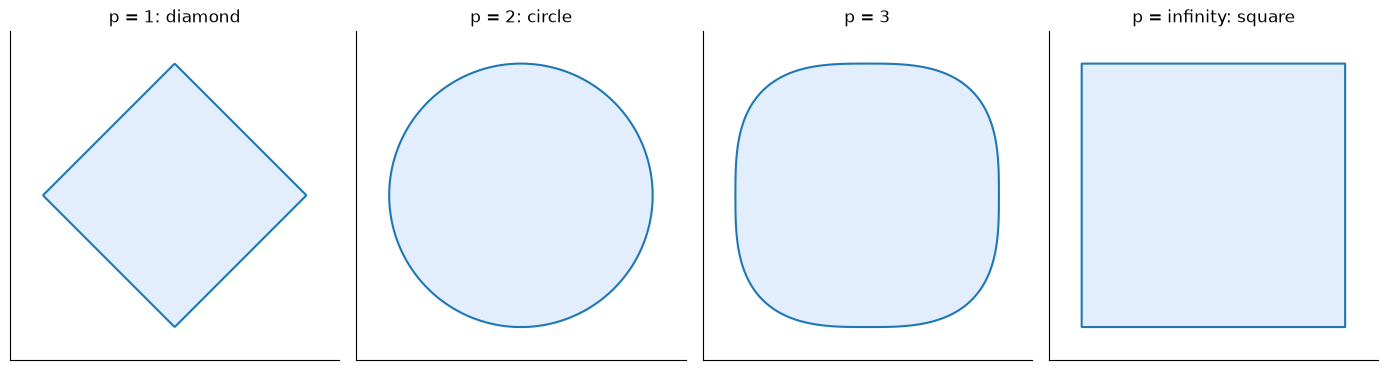

In [4]:
grid = np.linspace(-1.25, 1.25, 400)
gx, gy = np.meshgrid(grid, grid)
cases = [
    (1, 'p = 1: diamond'),
    (2, 'p = 2: circle'),
    (3, 'p = 3'),
    (np.inf, 'p = infinity: square'),
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (p, label) in zip(axes, cases):
    field = np.maximum(np.abs(gx), np.abs(gy)) if np.isinf(p) else (
        np.abs(gx) ** p + np.abs(gy) ** p
    ) ** (1 / p)
    ax.contourf(gx, gy, field, levels=[0, 1], colors=['#dbeafe'], alpha=0.8)
    ax.contour(gx, gy, field, levels=[1], colors='tab:blue')
    ax.set_title(label)
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 1.25)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

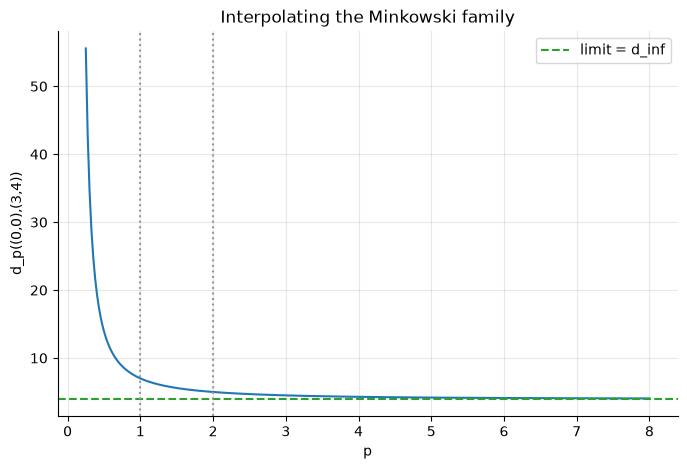

In [5]:
ps = np.linspace(0.25, 8, 300)
distances = [minkowski(x, y, p) for p in ps]

fig, ax = plt.subplots()
ax.plot(ps, distances)
ax.axhline(chebyshev(x, y), color='tab:green', ls='--', label='limit = d_inf')
ax.axvline(1, color='0.6', ls=':')
ax.axvline(2, color='0.6', ls=':')
ax.set(xlabel='p', ylabel='d_p((0,0),(3,4))', title='Interpolating the Minkowski family')
ax.legend()
plt.show()

## 2. Hamming and Jaccard

Hamming distance counts differing positions:

$$d_H(\mathbf{u},\mathbf{v})=\#\{i:u_i\neq v_i\}.$$

Jaccard similarity compares set overlap:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad d_J(A,B)=1-J(A,B),$$
with $J(\varnothing,\varnothing)=1$.

In [6]:
def hamming(u, v):
    if len(u) != len(v):
        raise ValueError('Hamming distance requires equal lengths')
    return sum(a != b for a, b in zip(u, v))


print('10110 vs 11110:', hamming('10110', '11110'))
print('101010 vs 010101:', hamming('101010', '010101'))
print('one-hot mismatch:', hamming((1, 0, 0), (0, 1, 0)))

10110 vs 11110: 1
101010 vs 010101: 6
one-hot mismatch: 2


In [7]:
def jaccard(A, B):
    A, B = set(A), set(B)
    union = A | B
    return len(A & B) / len(union) if union else 1.0


pairs = [
    ({1, 2, 3}, {2, 3, 4, 5}),
    ({1}, {1, 2, 3}),
    ({'cat', 'dog'}, {'car', 'bus'}),
]
for A, B in pairs:
    J = jaccard(A, B)
    print(f'A={sorted(A)}, B={sorted(B)} -> J={J:.3f}, dJ={1 - J:.3f}')
print('empty vs empty:', jaccard(set(), set()))

A=[1, 2, 3], B=[2, 3, 4, 5] -> J=0.400, dJ=0.600
A=[1], B=[1, 2, 3] -> J=0.333, dJ=0.667
A=['cat', 'dog'], B=['bus', 'car'] -> J=0.000, dJ=1.000
empty vs empty: 1.0


## 3. Distances between distributions

The notes introduce three metrics on probability laws. Hellinger and total
variation compare probability mass at matching outcomes. Wasserstein instead
moves mass across the outcome space, so it respects geometry.

$$H(p,q)=\sqrt{\tfrac12\sum_i(\sqrt{p_i}-\sqrt{q_i})^2},\qquad
\mathrm{TV}(p,q)=\tfrac12\sum_i|p_i-q_i|,$$

$$W_1(\mu,\nu)=\inf_{\gamma\in\Gamma(\mu,\nu)}\int|x-y|\,d\gamma(x,y)
=\int|F_\mu(x)-F_\nu(x)|\,dx\quad\text{on }\mathbb{R}.$$

In [8]:
def as_proba(p):
    arr = np.asarray(p, dtype=float)
    if arr.ndim == 0:
        arr = np.array([arr, 1 - arr])
    if arr.ndim != 1 or np.any(arr < 0) or not np.isclose(arr.sum(), 1):
        raise ValueError('expected a probability vector')
    return arr


def hellinger(p, q):
    p, q = as_proba(p), as_proba(q)
    return float(np.sqrt(0.5 * np.sum((np.sqrt(p) - np.sqrt(q)) ** 2)))


def total_variation(p, q):
    p, q = as_proba(p), as_proba(q)
    return float(0.5 * np.sum(np.abs(p - q)))


print('helpers ready')

helpers ready


In [9]:
examples = [
    ('identical', [0.5, 0.5], [0.5, 0.5]),
    ('disjoint', [1, 0], [0, 1]),
    ('Hellinger nearby', [0.9, 0.1], [0.8, 0.2]),
    ('TV nearby', [0.6, 0.4], [0.5, 0.5]),
]
for name, p, q in examples:
    print(f'{name:18s} H={hellinger(p, q):.4f}  TV={total_variation(p, q):.4f}')

identical          H=0.0000  TV=0.0000
disjoint           H=1.0000  TV=1.0000
Hellinger nearby   H=0.1003  TV=0.1000
TV nearby          H=0.0712  TV=0.1000


In [10]:
print('W1(delta_0, delta_3):', wasserstein_distance([0.0], [3.0]))
print('W1(delta_0, delta_1e-6):', wasserstein_distance([0.0], [1e-6]))

x = rng.uniform(0, 1, 20_000)
y = rng.uniform(0, 2, 20_000)
print('W1(U(0,1), U(0,2)):', round(wasserstein_distance(x, y), 4))

W1(delta_0, delta_3): 3.0
W1(delta_0, delta_1e-6): 1e-06
W1(U(0,1), U(0,2)): 0.4971


In [ ]:
try:
    integrate = np.trapezoid
except AttributeError:
    integrate = np.trapz

grid = np.linspace(-0.5, 2.5, 500)
f1, f2 = uniform.cdf(grid, 0, 1), uniform.cdf(grid, 0, 2)
area = integrate(np.abs(f1 - f2), grid)

fig, ax = plt.subplots()
ax.plot(grid, f1, label='CDF U(0,1)')
ax.plot(grid, f2, label='CDF U(0,2)')
ax.fill_between(grid, f1, f2, alpha=0.25, color='tab:orange')
ax.set(xlabel='x', ylabel='F(x)', title='W1 equals the shaded CDF area')
ax.legend()
plt.show()
print(f'numerical area = {area:.4f}, expected 0.5')

In [ ]:
p = np.array([0.6, 0.4])
qs = np.linspace(0.01, 0.99, 300)
hell = [hellinger(p, [q, 1 - q]) for q in qs]
tv = [total_variation(p, [q, 1 - q]) for q in qs]

fig, ax = plt.subplots()
ax.plot(qs, hell, label='Hellinger')
ax.plot(qs, tv, label='Total variation')
ax.axvline(0.6, color='0.5', ls='--', label='q = p')
ax.set(xlabel='q1', ylabel='distance', title='Bounded metrics on Bernoulli laws')
ax.legend()
plt.show()

for eps in [1.0, 0.1, 1e-6]:
    print(f'shift {eps:g}: W1={wasserstein_distance([0.0], [eps]):g}, TV=1, H=1')

## 4. Why the metric matters for k-NN

A nearest-neighbour classifier inherits its notion of 'near' from the metric.
Changing $d$ changes the Voronoi cells and the decision boundary even when
the data and $k$ are fixed.

In [ ]:
X, y = make_classification(
    n_samples=300, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, random_state=0,
)
h = 0.03
xx, yy = np.meshgrid(
    np.arange(X[:, 0].min() - 1, X[:, 0].max() + 1, h),
    np.arange(X[:, 1].min() - 1, X[:, 1].max() + 1, h),
)
grid = np.c_[xx.ravel(), yy.ravel()]
metrics = ['euclidean', 'manhattan', 'chebyshev']

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, metrics):
    clf = KNeighborsClassifier(n_neighbors=5, metric=metric).fit(X, y)
    Z = clf.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=14, edgecolor='k')
    ax.set_title(metric)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

## 5. Choosing a metric

| Situation | Recommended distance | Why |
| --- | --- | --- |
| Ordinary Euclidean geometry | Euclidean $d_2$ | Rotation invariant, familiar length |
| Grid-like movement or sparse high-dimensional vectors | Manhattan $d_1$ | Adds coordinate-wise effort |
| Worst-coordinate tolerance | Chebyshev $d_\infty$ | Only the largest difference matters |
| Tuning sensitivity to large deviations | Minkowski $d_p$ | $p$ interpolates $d_1$ to $d_\infty$ |
| Binary or categorical strings | Hamming | Counts mismatched positions |
| Tags or token sets | Jaccard | Rewards overlap relative to union |
| Comparing probability vectors | Hellinger or TV | Bounded, symmetric, support-sensitive |
| Comparing locations of mass | Wasserstein | Uses geometry; detects small shifts |

The last row is the key contrast: for $\delta_0$ and $\delta_\epsilon$,
Hellinger and TV stay at $1$ for every $\epsilon>0$, while $W_1=\epsilon$.

## Exercises

1. Prove the triangle inequality for $d_1$ and $d_\infty$ using the scalar triangle inequality.
2. Verify numerically that $d_1\geq d_2\geq d_\infty$ for random vectors in $\mathbb{R}^{10}$.
3. Show explicitly that $p=0.5$ violates the triangle inequality using $(1,0)$, $(0,1)$, $(0,0)$.
4. Find pairs of sets with Jaccard similarity $1/3$ and explain the construction.
5. Prove $H^2=1-\sum_i\sqrt{p_iq_i}$ and verify it on the `nearby` example.
6. For $N(0,1)$ and $N(\mu,1)$, derive $W_1$ analytically and check by simulation.
7. Repeat the k-NN boundary plot with `weights='distance'` and describe the change.